In [5]:
# 查看当前挂载的数据集目录, 该目录下的变更重启环境后会自动还原
# View dataset directory. 
# This directory will be recovered automatically after resetting environment. 
!ls /home/aistudio/data

data237460


In [10]:
!mkdir work1

In [11]:
# 查看工作区文件, 该目录下的变更将会持久保存. 请及时清理不必要的文件, 避免加载过慢.
# View personal work directory. 
# All changes under this directory will be kept even after reset. 
# Please clean unnecessary files in time to speed up environment loading. 
!ls /home/aistudio/work

In [13]:
# 如果需要进行持久化安装, 需要使用持久化路径, 如下方代码示例:
# If a persistence installation is required, 
# you need to use the persistence path as the following: 
!mkdir /home/aistudio/external-libraries
!pip install beautifulsoup4 -t /home/aistudio/external-libraries

mkdir: cannot create directory '/home/aistudio/external-libraries': File exists
Looking in indexes: https://mirror.baidu.com/pypi/simple/, https://mirrors.aliyun.com/pypi/simple/, https://pypi.tuna.tsinghua.edu.cn/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.0/143.0 kB 8.4 MB/s eta 0:00:00


In [14]:
# 同时添加如下代码, 这样每次环境(kernel)启动的时候只要运行下方代码即可: 
# Also add the following code, 
# so that every time the environment (kernel) starts, 
# just run the following code: 
import sys 
sys.path.append('/home/aistudio/external-libraries')

# slice 操作

In [24]:
import numpy as np
index = slice(0,10,2) #syntax sugar slice(start,end,step)

print(index)
a = np.array([10,20,30,40,50,60,70,80,90,100,110,120,130])
b = a[0:10:2]
c = a[0:10:]
d =a[0:10]
e = a[:10]
f = a[0:]
print(b)
print(c)
print(d)
print(e)
print(f)
g = a[:]
print(g)
h = a[::]
print(h)
i = a[::2]
i = a[slice(0,13,2)]
print(i)

slice(0, 10, 2)
[10 30 50 70 90]
[ 10  20  30  40  50  60  70  80  90 100]
[ 10  20  30  40  50  60  70  80  90 100]
[ 10  20  30  40  50  60  70  80  90 100]
[ 10  20  30  40  50  60  70  80  90 100 110 120 130]
[ 10  20  30  40  50  60  70  80  90 100 110 120 130]
[ 10  20  30  40  50  60  70  80  90 100 110 120 130]
[ 10  30  50  70  90 110 130]


## inverse slice index 

In [35]:
import numpy as np
index = slice(0,10,2) #syntax sugar slice(start,end,step)

print(index)
a = np.array([10,20,30,40,50,60,70,80,90,100,110,120,130])
length = len(a)
print(a.shape)
print(length)
length = a.shape[0]

b = a[-1]
print(b)
c = a[-1:-3:-1]
print(c)
d = a[-1:-14:-1]
d = a[-1:-1+(-length):-1]
print(d)
e = a[::-1]
print(e)
f = a[::-2]
print(f)

slice(0, 10, 2)
(13,)
13
130
[130 120]
[130 120 110 100  90  80  70  60  50  40  30  20  10]
[130 120 110 100  90  80  70  60  50  40  30  20  10]
[130 110  90  70  50  30  10]


## 笛卡尔积 

In [37]:

import itertools
a = np.array([0,1,2])
b = np.array([4,5])
x = list(itertools.product(a, b))

print(x)

[(0, 4), (0, 5), (1, 4), (1, 5), (2, 4), (2, 5)]


# 例3-1 水平方向平移50，垂直方向平移25
** matrix如何表达 **
$$ M = 
\begin{bmatrix}
1 & 0 & 50 \\
0 & 1 & 25 \\
0 & 0 & 1
\end{bmatrix}
$$

$$ P' = M P $$
$$  $$



## using  for loop 

In [19]:
x = 10
y = 10
P =np.array([x,y,1])   
P_prime = M @ P
    
x_prime = P_prime[0]
y_prime = P_prime[1]
x_prime = int(x_prime)
y_prime = int(y_prime)
print(P_prime)
    # range check 
    ##???     
#if x_prime >= 0 and x_prime < width and y_prime >= 0 and y_prime < height:
#    g[y_prime,x_prime] = f[y,x]
#    print('hello')
#    pritn(f[y,x])

[60. 35.  1.]


##  forward mapping 

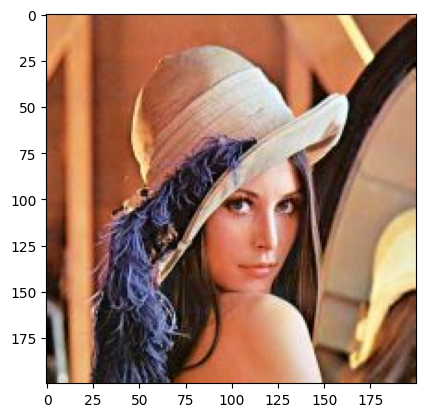

(200, 200, 3)
(200, 200, 3)


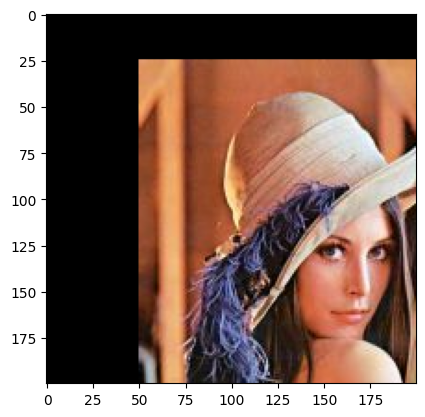

In [30]:
#  forward mapping 
import cv2
import numpy as np
import matplotlib.pyplot as plt
image = cv2.imread('/home/aistudio/work/lena.jpg')
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
plt.imshow(image)
plt.show()
print(image.shape)
height = image.shape[0]
width = image.shape[1]
channels = image.shape[2]
f = image 
g = np.zeros_like(f)
print(g.shape)
M = np.array([[1,0,50],[0,1,25],[0,0,1]],dtype= np.float64)
for x in range(0,width):
    for y in range(0,height):
     P =np.array([x,y,1])   
     P_prime = M @ P
     
     x_prime = P_prime[0]
     y_prime = P_prime[1]
     x_prime = int(x_prime)
     y_prime = int(y_prime)
   
     if x_prime >= 0 and x_prime < width and y_prime >= 0 and y_prime < height:     
        g[y_prime,x_prime,:] = f[y,x,:]
#print(g)
plt.imshow(g)
plt.show()
     


### backward mapping 

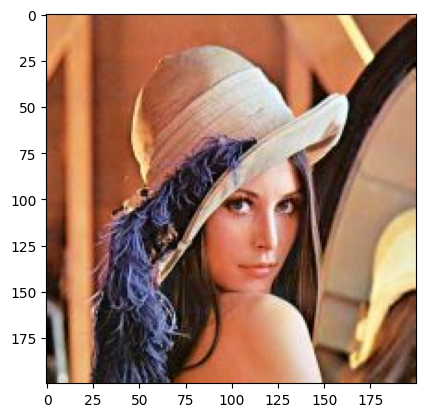

(200, 200, 3)
(200, 200, 3)


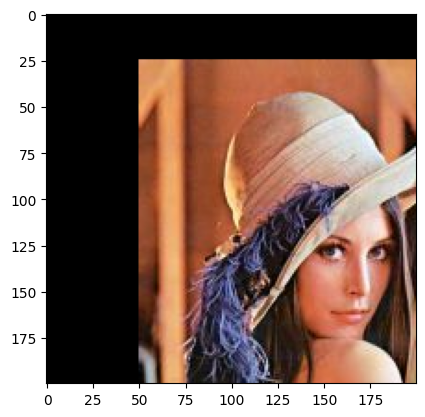

In [31]:
# backward mapping 

import cv2
import numpy as np
import matplotlib.pyplot as plt
image = cv2.imread('/home/aistudio/work/lena.jpg')
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
plt.imshow(image)
plt.show()
print(image.shape)
height = image.shape[0]
width = image.shape[1]
channels = image.shape[2]
f = image 
g = np.zeros_like(f)
print(g.shape)
M = np.array([[1,0,50],[0,1,25],[0,0,1]],dtype= np.float64)
M_inv = np.linalg.inv(M)

for x_prime in range(0,width):
    for y_prime in range(0,height):
        P_prime =np.array([x_prime,y_prime,1])   
        P = M_inv @ P_prime
        x = P[0]
        y = P[1]
        x = int(x)
        y = int(y)
        if x>= 0 and x < width and y >= 0 and y < height: 
            g[y_prime,x_prime] = f[y,x]

plt.imshow(g) 
plt.show()



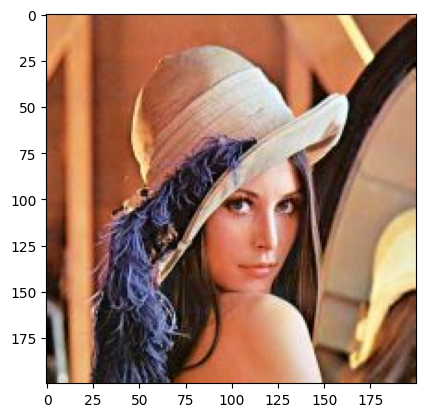

(200, 200, 3)


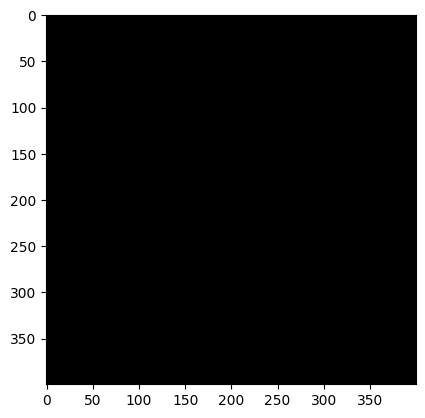

(200, 200, 3)


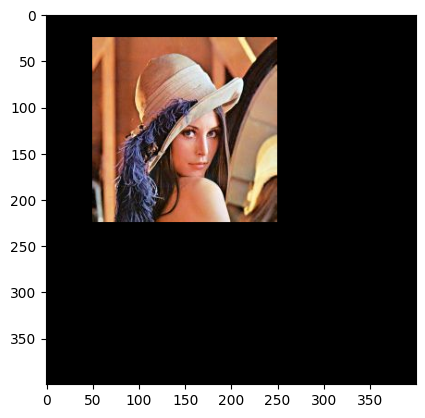

In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
image = cv2.imread('/home/aistudio/work/lena.jpg')
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
plt.imshow(image)
plt.show()
print(image.shape)
height = image.shape[0]
width = image.shape[1]
channels = image.shape[2]
image_translated = np.zeros((2*height,2*width,channels),dtype = np.uint8)
plt.imshow(image_translated)
plt.show()
roi = image_translated[25:25+height,50:50+width,:]
#roi[:,:,:] = image[:,:,:]
roi[:] = image[:] #逐行赋值

roi[:,:] = image[:,:] #逐像素赋值
roi[:,...] = image[:,...] #逐像素赋值简略写法
print(roi.shape)
plt.imshow(image_translated)
plt.show()

using opencv warpaffine

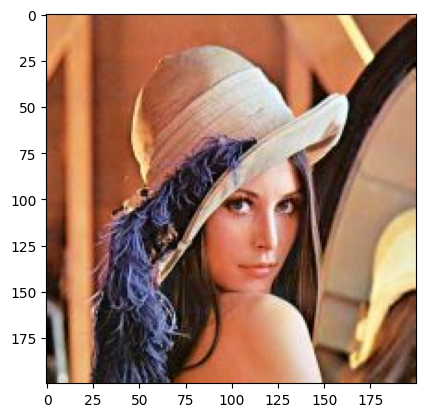

(200, 200, 3)


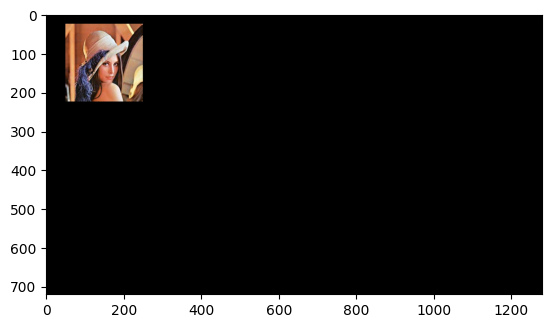

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
image = cv2.imread('/home/aistudio/work/lena.jpg')
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
plt.imshow(image)
plt.show()
print(image.shape)
height = image.shape[0]
width = image.shape[1]
channels = image.shape[2]
M = np.array([[1,0,50],[0,1,25]],dtype= np.float64)
img_opencv = cv2.warpAffine(image,M,(1280,720))
plt.imshow(img_opencv)
plt.show()

# 例3-2 using cv2.warpAffine()


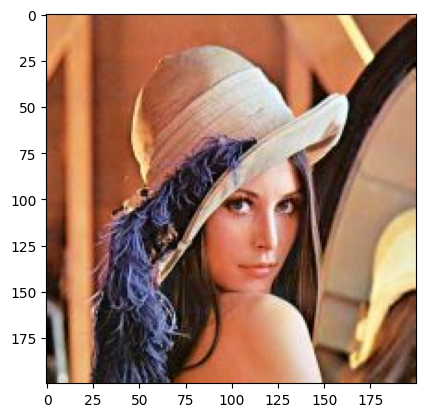

(200, 200, 3)


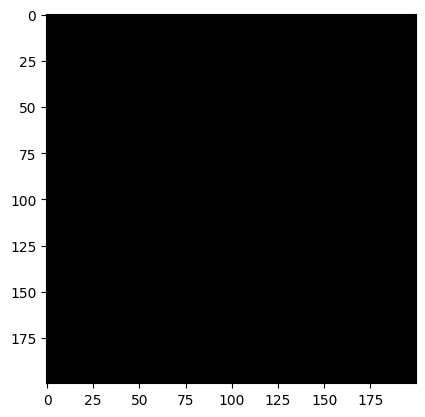

(175, 150, 3)


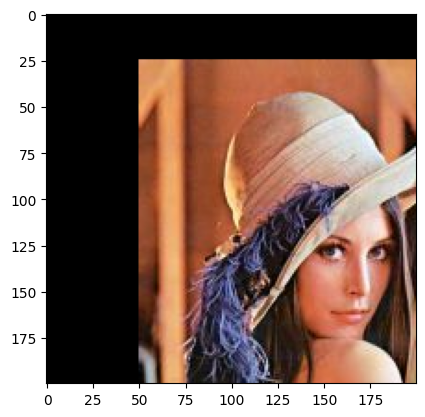

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
image = cv2.imread('/home/aistudio/work/lena.jpg')
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
plt.imshow(image)
plt.show()
print(image.shape)
height = image.shape[0]
width = image.shape[1]
image_translated = np.zeros((height,width,3),dtype = np.uint8)
plt.imshow(image_translated)
plt.show()
roi = image_translated[25:height,50:width,:]
#roi[:,:,:] = image[:,:,:]
roi[:,:,:] = image[0:roi.shape[0],0:roi.shape[1],:]
print(roi.shape)
plt.imshow(image_translated)
plt.show()

# 例3-3  图像旋转

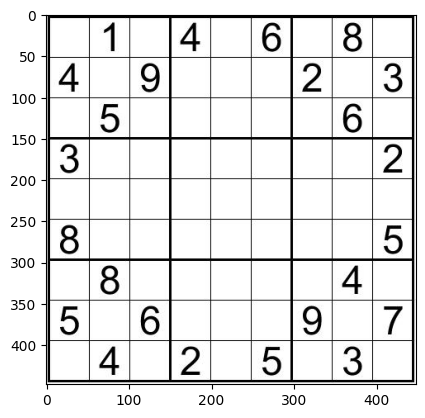

[[ 50.  50.   1.]
 [200.  50.   1.]
 [ 50. 200.   1.]]
[[  1.2666667    0.6        -83.333336  ]
 [ -0.33333334   1.          66.66665   ]
 [  0.           0.           0.9999999 ]]
[[ 50. 200.  50.]
 [ 50.  50. 200.]
 [  1.   1.   1.]]
[[ 10. 200. 100.]
 [100.  50. 250.]
 [  1.   1.   1.]]


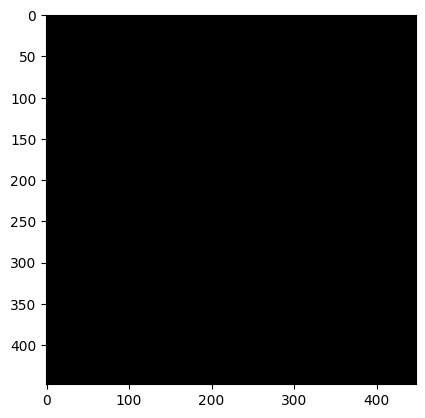

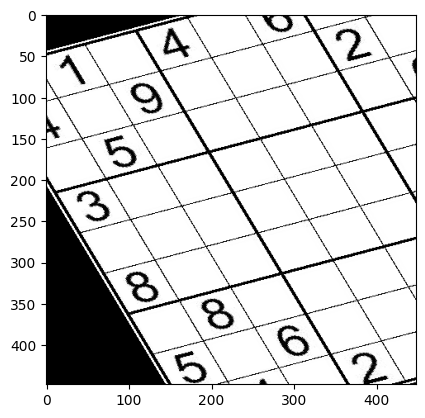

In [2]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt


image  = cv2.imread('/home/aistudio/work/sudoku2.jpg')
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
plt.imshow(image)
plt.show()

pointsfrom = np.array([[50,50,1],[200,50,1],[50,200,1]],dtype=np.float32)
pointsto  =  np.array([[10,100,1],[200,50,1],[100,250,1]],dtype=np.float32)
#M = cv2.getAffineTransform(pointsfrom,pointsto)
A = np.transpose(pointsfrom)
B  = np.transpose(pointsto)
M = np.dot(B,np.linalg.inv(A))

print(pointsfrom)
print(M)
print(A)
print(B)

image_transformed = np.zeros_like(image)
plt.imshow(image_transformed)
plt.show()

for x in range(0,image.shape[1]):
    for y in range(0,image.shape[0]):
        posto = np.array([[x],[y],[1]],dtype = np.float32) 
        posfrom = np.dot(np.linalg.inv(M),posto)
        #print(posfrom)
        x_from = posfrom[0]
        y_from = posfrom[1]
        #print(x_from)
        #print(x_from.dtype)
        #print(x_from.shape)
        x_from = np.around(x_from)
        y_from = np.around(y_from)
        x_from = x_from.astype(np.int32)
        y_from = y_from.astype(np.int32)
        if(x_from>=0 and x_from <image.shape[1] and y_from >=0 and y_from < image.shape[0]):
            image_transformed[y,x] = image[y_from,x_from]


plt.imshow(image_transformed)
plt.show()


请点击[此处](https://ai.baidu.com/docs#/AIStudio_Project_Notebook/a38e5576)查看本环境基本用法.  <br>
Please click [here ](https://ai.baidu.com/docs#/AIStudio_Project_Notebook/a38e5576) for more detailed instructions. 

# 例3-4 图像缩放


$$ M = 
\begin{bmatrix}
1.2 & 0 & 0 \\
0 & 1.2 & 0 \\
0 & 0 & 1
\end{bmatrix}
$$

$$ M^{-1} = 
\begin{bmatrix}
1/1.2 & 0 & 0 \\
0 & 1/1.2 & 0 \\
0 & 0 & 1
\end{bmatrix}
$$




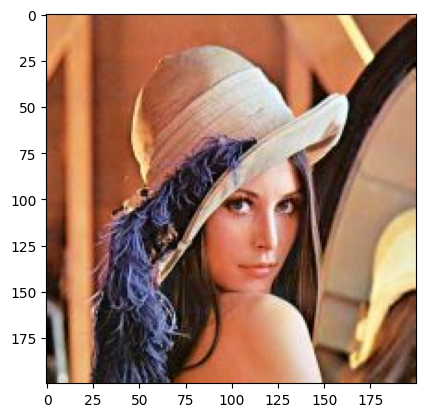

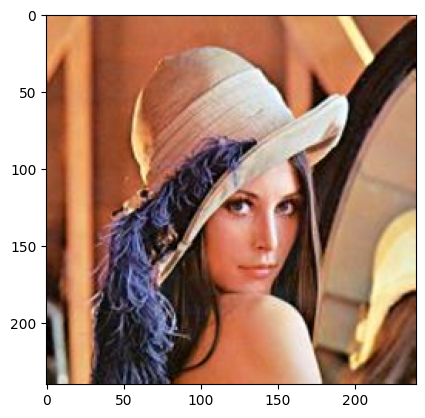

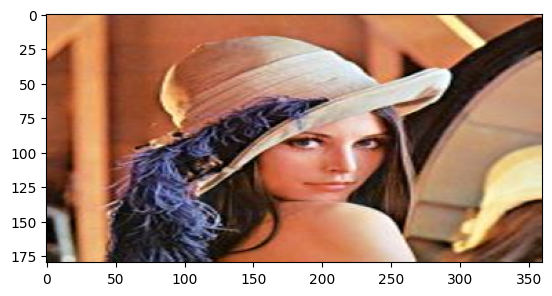

In [5]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt


image  = cv2.imread('/home/aistudio/work/lena.jpg')
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
plt.imshow(image)
plt.show()


image1 = cv2.resize(image,None,fx = 1.2,fy = 1.2,interpolation = cv2.INTER_CUBIC)
plt.imshow(image1)
plt.show()

width = 360
height = 180
image2 = cv2.resize(image,(width,height),interpolation = cv2.INTER_CUBIC)
plt.imshow(image2)
plt.show()


## 图像缩放 利用切片

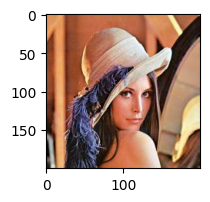

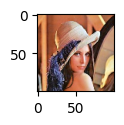

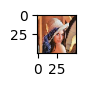

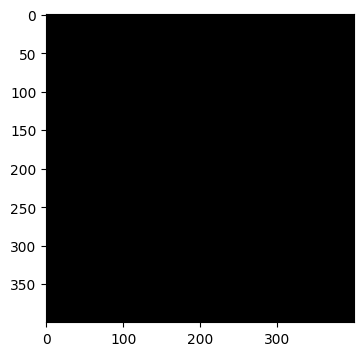

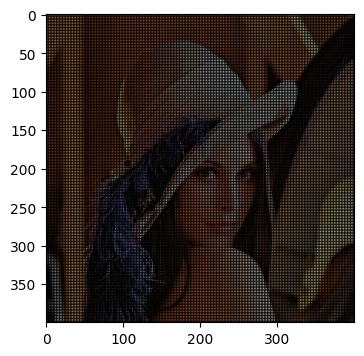

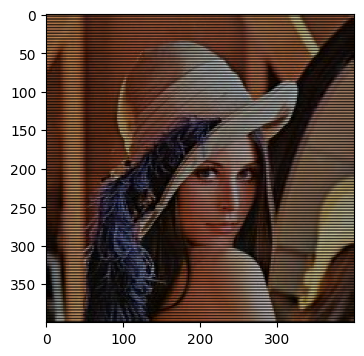

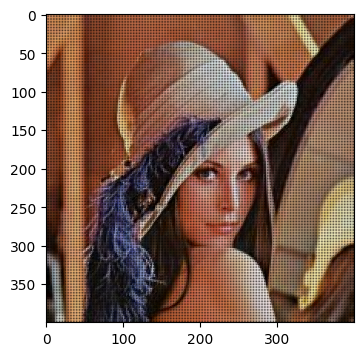

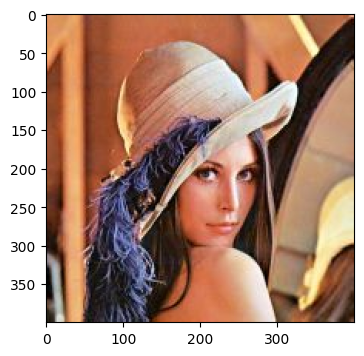

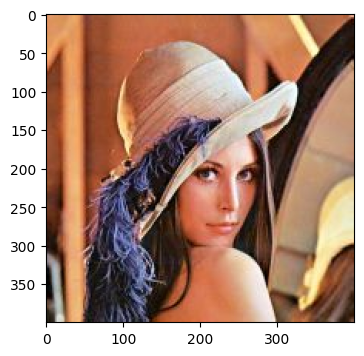

In [35]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi']=100

image  = cv2.imread('/home/aistudio/work/lena.jpg')
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
plt.figure(figsize=(2,2),dpi=100)
plt.imshow(image)
plt.show()

#scaleDown = image[0:200:2,0:200:2]
scaleDown = image[::2,::2]
#plt.rcParams['figure.dpi']=100
plt.figure(figsize = (1,1),dpi=100)
plt.imshow(scaleDown)
plt.show()

scaleDown = image[::4,::4]
#plt.rcParams['figure.dpi']=100
plt.figure(figsize=(0.5,0.5),dpi=100)
plt.imshow(scaleDown)
plt.show()

height,width,channels = image.shape
scaleUp = np.zeros((2*height,2*width,channels),dtype=np.uint8)
plt.figure(figsize=(4,4),dpi=100)
plt.imshow(scaleUp)
plt.show()
roi00 = scaleUp[0::2,0::2]
roi00[:] = image[:]
plt.figure(figsize=(4,4),dpi=100)
plt.imshow(scaleUp)
plt.show()

roi01 = scaleUp[0::2,1::2]
roi01[:] = image[:]
plt.figure(figsize=(4,4),dpi=100)
plt.imshow(scaleUp)
plt.show()

roi10 = scaleUp[1::2,0::2]
roi10[:] = image[:]
plt.figure(figsize=(4,4),dpi=100)
plt.imshow(scaleUp)
plt.show()

roi11 = scaleUp[1::2,1::2]
roi11[:] = image[:]
plt.figure(figsize=(4,4),dpi=100)
plt.imshow(scaleUp)
plt.show()



plt.figure(figsize=(4,4),dpi = 100)
plt.imshow(scaleUp)
plt.show()



# 例3-5 图像旋转

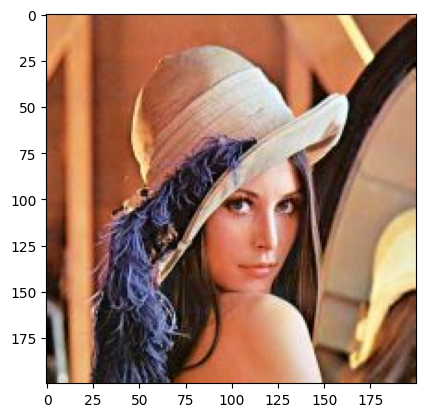

200


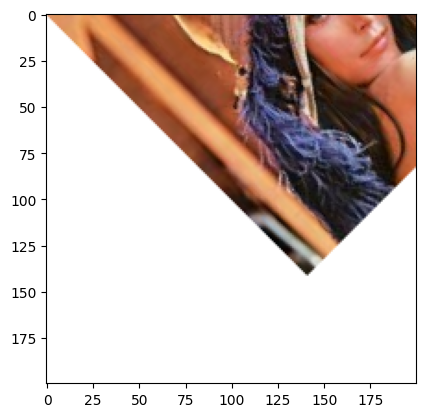

In [3]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt


image  = cv2.imread('/home/aistudio/work/lena.jpg')
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
plt.imshow(image)
plt.show()

height , width, channels = image.shape
print(height)
center = (width/2.0,height/2.0)
center = (0,0)
M = cv2.getRotationMatrix2D(center,45,1)
image_transformed = cv2.warpAffine(image,M,(width,height),borderValue=(255,255,255))
plt.imshow(image_transformed)
plt.show()


In [ ]:
# 例3-6 边缘无剪切旋转

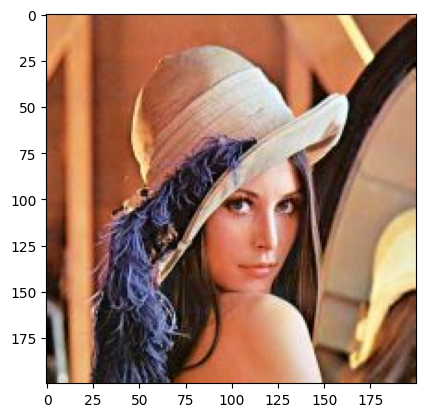

200


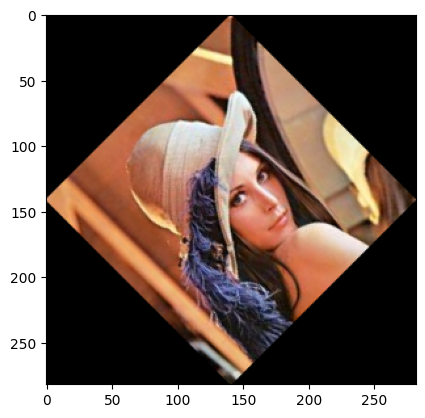

In [19]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt


image  = cv2.imread('/home/aistudio/work/lena.jpg')
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
plt.imshow(image)
plt.show()

height , width, channels = image.shape
print(height)
theta = 45
alpha = np.cos(np.pi/180.0*theta)
beta  =  np.sin(np.pi/180.0*theta)


cx = width/2.0
cy = height/2.0
tx = (1-alpha)*cx - beta*cy
ty = beta*cx + (1-alpha)*cy

M = np.array([[alpha ,beta ,tx],[-beta ,alpha ,ty]],dtype = np.float32)

bound_width  = int(height* np.abs(beta) + width * np.abs(alpha))
bound_height  = int(height * np.abs(alpha) + width * np.abs(beta))

M[0,2] += bound_width/2.0 -cx
M[1,2] += bound_height/2.0-cy



#M = cv2.getRotationMatrix2D(center,45,1)
image_transformed = cv2.warpAffine(image,M,(bound_width,bound_height))
plt.imshow(image_transformed)
plt.show()


# 例3-7 图像剪切


## deep copy shallow copy

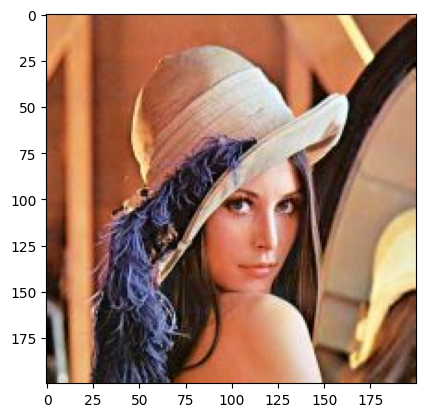

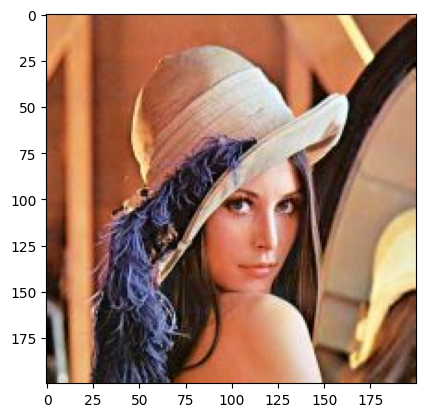

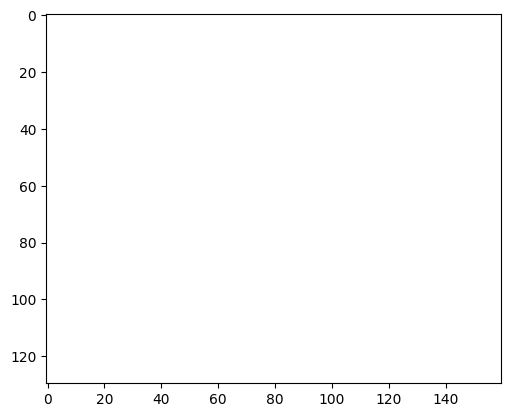

In [41]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt


image  = cv2.imread('/home/aistudio/work/lena.jpg')
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
plt.imshow(image)
plt.show()
roi = image[30:160,20:180,:]


roi = roi.copy()
roi[:] = 255 
plt.imshow(image)
plt.show()
plt.imshow(roi)
plt.show()






In [ ]:
# 例3-8 not supported yet

In [ ]:
import cv2 
import numpy as np 


# 例3-9 镜像变换

## up and down 

200 200 3


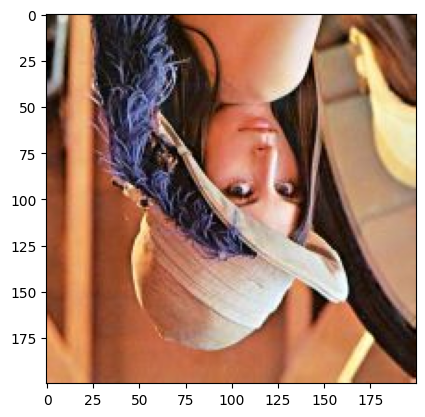

In [46]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt

image  = cv2.imread('/home/aistudio/work/lena.jpg')
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
updown_image = image.copy()
updown_image[:,:,:] = 0
updown_image[0:0+image.shape[0]:1]= image[-1:-1+(-image.shape[0]):-1]

height,width,channels = image.shape
updown_image[0:0+height:1]= image[-1:-1+(-height):-1]
print(height,width,channels)
plt.imshow(updown_image)
plt.show()

## left and right

200 200 3


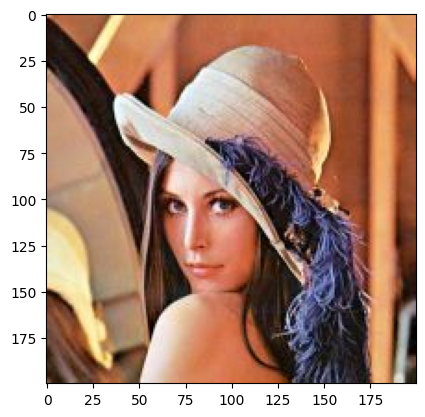

In [49]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt

image  = cv2.imread('/home/aistudio/work/lena.jpg')
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
leftright_image = image.copy()
leftright_image[:,:,:] = 0
leftright_image[:,0:0+image.shape[1]:1]= image[:,-1:-1+(-image.shape[1]):-1]

height,width,channels = image.shape
leftright_image[:,0:0+width:1]= image[:,-1:-1+(-width):-1]
print(height,width,channels)
plt.imshow(leftright_image)
plt.show()

## symetric transform

200 200 3


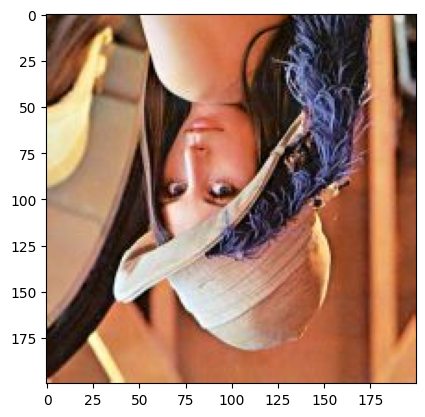

In [51]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt

image  = cv2.imread('/home/aistudio/work/lena.jpg')
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
updown_image = image.copy()
updown_image[:,:,:] = 0
updown_image[0:0+image.shape[0]:1]= image[-1:-1+(-image.shape[0]):-1]
updown_image_copy = updown_image.copy()

height,width,channels = image.shape
leftright_image[:,0:0+width:1]= updown_image_copy[:,-1:-1+(-width):-1]
print(height,width,channels)
plt.imshow(leftright_image)
plt.show()

mymodules
(200, 200, 3)


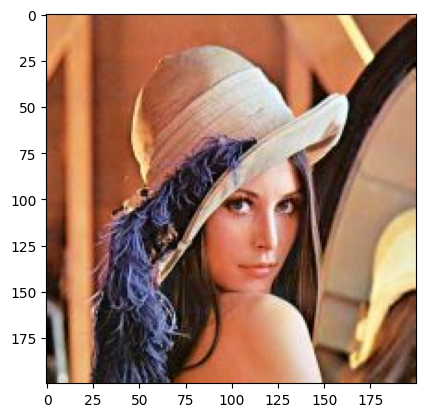

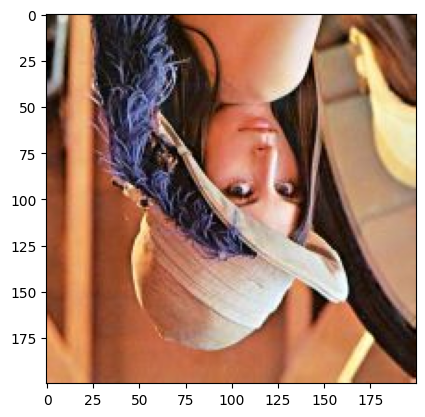

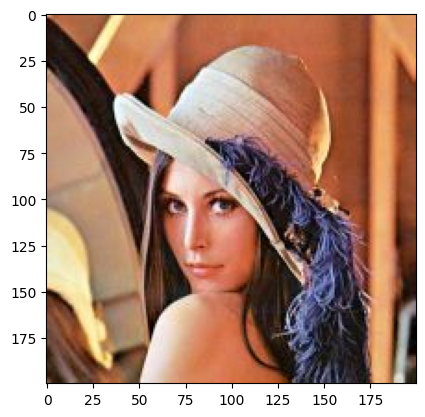

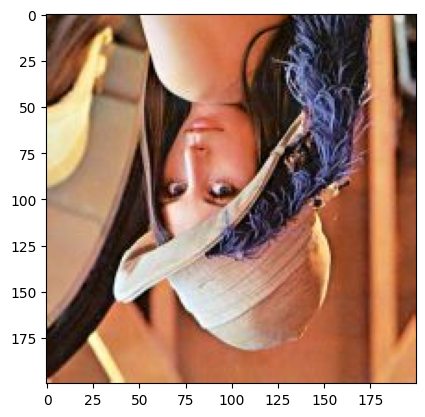

In [2]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt
from ayit import guo
image  = cv2.imread('/home/aistudio/work/lena.jpg')
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
image_flipped_updown = guo.flipupdown(image)
image_flipped_leftright = guo.flip_left_right(image)
image_diagonal = guo.flip_digonal(image)
print(image_flipped_leftright.shape)
plt.imshow(image)
plt.show()

plt.imshow(image_flipped_updown)
plt.show()

plt.imshow(image_flipped_leftright)
plt.show()

plt.imshow(image_diagonal)
plt.show()



# 例3-10

In [3]:
pointsfrom2 = np.array([[50,60,1],[560,50,1],[30,580,1],[590,590,1]],dtype=np.float32)
pointsto2  =  np.array([[0,0,1],[600,0,1],[0,600,1],[600,600,1]],dtype=np.float32)
A2 = np.transpose(pointsfrom2)
B2 = np.transpose(pointsfrom2)
A2T = np.transpose(A2)
A2A2T = np.dot(A2,A2T)
A2A2T_inv = np.linalg.inv(A2A2T)
print(A2A2T)
print(A2A2T_inv)
M2 =    np.dot(B2,np.dot(A2T,np.linalg.inv(A2A2T)))
print(M2)


[[6.651e+05 3.965e+05 1.230e+03]
 [3.965e+05 6.906e+05 1.280e+03]
 [1.230e+03 1.280e+03 4.000e+00]]
[[ 3.4862026e-06 -3.5978601e-08 -1.0604941e-03]
 [-3.5978601e-08  3.5590901e-06 -1.1278455e-03]
 [-1.0604941e-03 -1.1278455e-03  9.3701249e-01]]
[[ 9.9999994e-01 -6.0303137e-08 -2.5629997e-05]
 [-7.3341653e-08  9.9999988e-01 -2.5629997e-05]
 [-5.8207661e-11 -2.3283064e-10  9.9999994e-01]]


In [30]:
print(A2)
print(B2)
A22 = np.dot(A2,np.transpose(A2))
A22_inv = np.linalg.inv(A22)
print(A22_inv)

[[ 50. 560.  30. 590.]
 [ 60.  50. 580. 590.]
 [  1.   1.   1.   1.]]
[[ 50. 560.  30. 590.]
 [ 60.  50. 580. 590.]
 [  1.   1.   1.   1.]]
[[ 3.4862026e-06 -3.5978601e-08 -1.0604941e-03]
 [-3.5978601e-08  3.5590901e-06 -1.1278455e-03]
 [-1.0604941e-03 -1.1278455e-03  9.3701249e-01]]


(412, 640, 3)


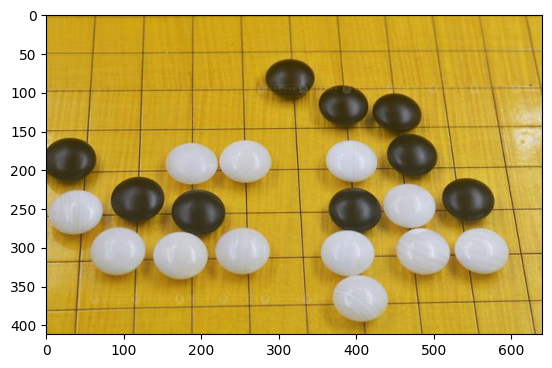

[[ 1.23918639e+00  4.76610151e-02 -6.48189806e+01]
 [ 2.51875586e-02  1.28456549e+00 -7.83333072e+01]
 [ 7.68191876e-05  1.89906773e-04  1.00000000e+00]]
[[ 50. 560.  30. 590.]
 [ 60.  50. 580. 590.]
 [  0.   0.   0.   0.]
 [  1.   1.   1.   1.]]
[[  0. 600.   0. 600.]
 [  0.   0. 600. 600.]
 [  0.   0.   0.   0.]
 [  1.   1.   1.   1.]]
[[ 50.  60.   0.   1.]
 [560.  50.   0.   1.]
 [ 30. 580.   0.   1.]
 [590. 590.   0.   1.]]
[[ 1.1190710e+00 -1.1549107e-02  0.0000000e+00 -4.0418583e+01]
 [-9.8262122e-04  1.1316828e+00  0.0000000e+00 -6.1836308e+01]
 [ 0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00]
 [-1.1641532e-10  1.1641532e-10  0.0000000e+00  1.0000000e+00]]
[[8.916667e-01 8.333393e-03 0.000000e+00 3.750000e+01]
 [6.810296e-08 8.833334e-01 0.000000e+00 5.500000e+01]
 [0.000000e+00 0.000000e+00 0.000000e+00 0.000000e+00]
 [5.820766e-11 5.820766e-11 0.000000e+00 1.000000e+00]]
[[ 50. 560.  30. 590.]
 [ 60.  50. 580. 590.]
 [  0.   0.   0.   0.]
 [  1.   1.   1.   1.]]


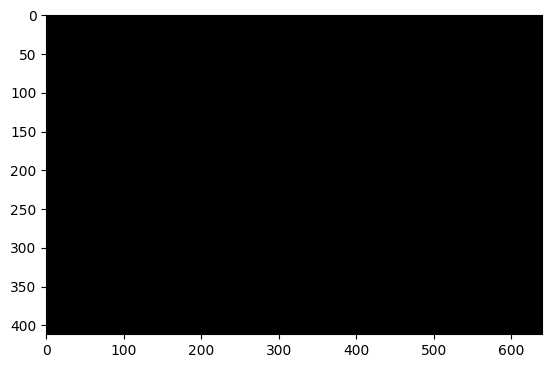

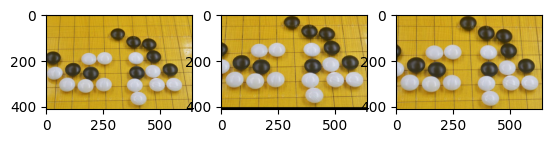

In [23]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt


image  = cv2.imread('/home/aistudio/work/weiqi1.jpg')
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
print(image.shape)
plt.imshow(image)
plt.show()

pointsfrom = np.array([[50,60,0,1],[560,50,0,1],[30,580,0,1],[590,590,0,1]],dtype=np.float32)
pointsto  =  np.array([[0,0,0,1],[600,0,0,1],[0,600,0,1],[600,600,0,1]],dtype=np.float32)

pointsfrom3 = np.array([[50,60],[560,50],[30,580],[590,590]],dtype=np.float32)
pointsto3  =  np.array([[0,0],[600,0],[0,600],[600,600]],dtype=np.float32)
M3 = cv2.getPerspectiveTransform(pointsfrom3,pointsto3)
dstImage = cv2.warpPerspective(image,M3,[640,412])
print(M3)

pointsfrom2 = np.array([[50,60,1],[560,50,1],[30,580,1],[590,590,1]],dtype=np.float32)
pointsto2  =  np.array([[0,0,1],[600,0,1],[0,600,1],[600,600,1]],dtype=np.float32)
A2 = np.transpose(pointsfrom2)
B2 = np.transpose(pointsfrom2)
M2 =    np.dot(B2,np.linalg.inv(np.dot(A2,np.transpose(A2))))

A = np.transpose(pointsfrom)
B  = np.transpose(pointsto)
print(A) 
print(B)
M = np.dot(B,np.linalg.pinv(A))
M_inv = np.dot(A,np.linalg.pinv(B))

print(pointsfrom)
print(M)
print(M_inv)
print(A)
print(B)

image_transformed = np.zeros_like(image)
plt.imshow(image_transformed)
plt.show()

for x in range(0,image.shape[1]):
    for y in range(0,image.shape[0]):
        posto = np.array([[x],[y],[0],[1]],dtype = np.float32) 
        posfrom = np.dot(np.linalg.pinv(M),posto)
        #print(posfrom)
        x_from = posfrom[0]
        y_from = posfrom[1]
        #print(x_from)
        #print(x_from.dtype)
        #print(x_from.shape)
        x_from = np.around(x_from)
        y_from = np.around(y_from)
        x_from = x_from.astype(np.int32)
        y_from = y_from.astype(np.int32)
        if(x_from>=0 and x_from <image.shape[1] and y_from >=0 and y_from < image.shape[0]):
            image_transformed[y,x] = image[y_from,x_from]

plt.subplot(1,3,1)
plt.imshow(image)
plt.subplot(1,3,2)
plt.imshow(image_transformed)
plt.subplot(1,3,3)
plt.imshow(dstImage)
plt.show()



# 例3-11

In [84]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt
import math
x = 3 
y = 5 

centerx = 0
centery = 0
rx = x- centerx 
ry = y- centery
r =   math.sqrt(rx*rx + ry*ry)
theta = math.atan2(ry, rx)/math.pi*180.0
print(r)
print(theta)
rx1 = np.array(rx,dtype = np.float32)
ry1 = np.array(ry,dtype = np.float32)
r1,theta1  =cv2.cartToPolar(rx1,ry1,angleInDegrees = True)
print(r1)
print(theta1)
print(r1.shape)

x1, y1 = cv2.polarToCart(r1,theta1,angleInDegrees = True)
print(x1[0])
print(y1[0])





5.830951894845301
59.03624346792648
[[5.8309517]]
[[59.039936]]
(1, 1)
[2.9996784]
[5.000194]


# 例3-12

(512, 512, 3)


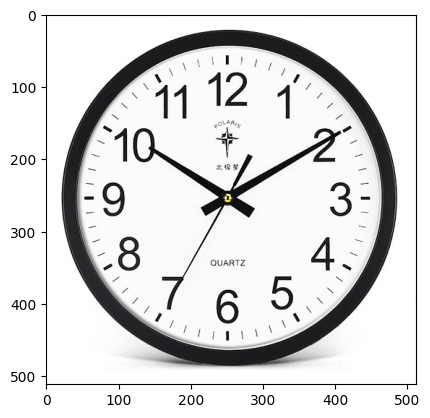

363


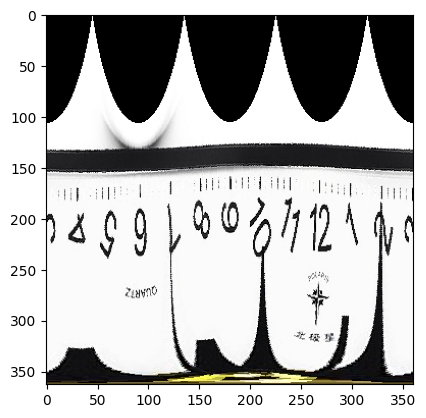

In [5]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt
import math
image = cv2.imread('/home/aistudio/work/clock.jpg')
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
height,width,channels = image.shape
print(image.shape)
plt.imshow(image)
plt.show()

rmax = math.hypot(width/2.0,height/2.0)
rmax = int(np.ceil(rmax))
print(rmax)
centerx = width/2.0
centery = height/2.0
for x in range(0,width):
    for y in range(0,height):
        rx = x- centerx 
        ry = y- centery
        r =   math.sqrt(rx*rx + ry*ry)
        theta = math.atan2(ry, rx)/math.pi*180.0
        #if(x<10 and y < 10):
        #    print('r=%f'%r)
        #    print('theta = %f'%theta)


image_polar = np.zeros((rmax,360,3),dtype=np.uint8)
#print(image_polar)
for r in range(0,rmax):
    for theta in range(0,360):
        x1 = r*np.cos(theta/180.0*np.pi)
        y1 = r*np.sin(theta/180.0*np.pi)
        x = centerx + x1
        y = centery + y1
        x = int(np.around(x))
        y = int(np.around(y))
        if(x>=0 and x < width and y>=0 and y <height):
            image_polar[r,theta,:] = image[y,x,:]



image_polar = cv2.flip(image_polar,0)

plt.imshow(image_polar)
plt.show()

# log polar







## log polar

(512, 512, 3)


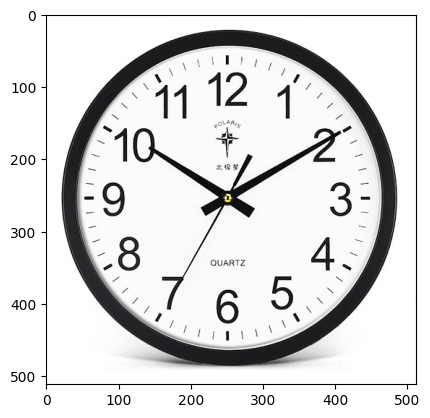

(512,)
rmax = 362.038672
rmax_log = 5.891751


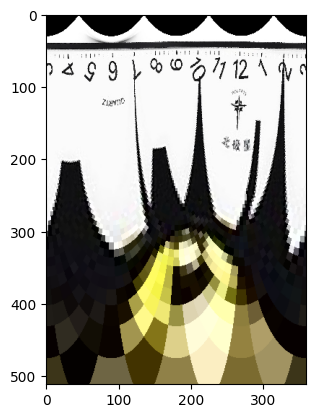

[0.         0.01152985 0.02305969 0.03458954 0.04611938 0.05764923
 0.06917907 0.08070892 0.09223876 0.10376861 0.11529845 0.1268283
 0.13835815 0.14988799 0.16141784 0.17294768 0.18447753 0.19600737
 0.20753722 0.21906706 0.23059691 0.24212675 0.2536566  0.26518645
 0.27671629 0.28824614 0.29977598 0.31130583 0.32283567 0.33436552
 0.34589536 0.35742521 0.36895506 0.3804849  0.39201475 0.40354459
 0.41507444 0.42660428 0.43813413 0.44966397 0.46119382 0.47272366
 0.48425351 0.49578336 0.5073132  0.51884305 0.53037289 0.54190274
 0.55343258 0.56496243 0.57649227 0.58802212 0.59955196 0.61108181
 0.62261166 0.6341415  0.64567135 0.65720119 0.66873104 0.68026088
 0.69179073 0.70332057 0.71485042 0.72638026 0.73791011 0.74943996
 0.7609698  0.77249965 0.78402949 0.79555934 0.80708918 0.81861903
 0.83014887 0.84167872 0.85320856 0.86473841 0.87626826 0.8877981
 0.89932795 0.91085779 0.92238764 0.93391748 0.94544733 0.95697717
 0.96850702 0.98003686 0.99156671 1.00309656 1.0146264  1.026156

In [6]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt
import math
image = cv2.imread('/home/aistudio/work/clock.jpg')
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
height,width,channels = image.shape
print(image.shape)
plt.imshow(image)
plt.show()

rmax = math.hypot(width/2.0,height/2.0)
rmax_log = np.log(rmax)
r_nums = 512
r_log_values = np.linspace(0,rmax_log,512)
print(r_log_values.shape)
#rmax = int(np.ceil(rmax))
print('rmax = %f'%rmax)
print('rmax_log = %f' %rmax_log)
centerx = width/2.0
centery = height/2.0
for x in range(0,width):
    for y in range(0,height):
        rx = x- centerx 
        ry = y- centery
        r =   math.sqrt(rx*rx + ry*ry)
        theta = math.atan2(ry, rx)/math.pi*180.0
        #if(x<10 and y < 10):
        #    print('r=%f'%r)
        #    print('theta = %f'%theta)


image_polar = np.zeros((r_nums,360,3),dtype=np.uint8)
#print(image_polar)
for r_index in range(0,r_nums):
    for theta in range(0,360):
        r = np.exp(r_log_values[r_index])
        x1 = r*np.cos(theta/180.0*np.pi)
        y1 = r*np.sin(theta/180.0*np.pi)
        x = centerx + x1
        y = centery + y1
        x = int(np.around(x))
        y = int(np.around(y))
        if(x>=0 and x < width and y>=0 and y <height):
            image_polar[r_index,theta,:] = image[y,x,:]



image_polar = cv2.flip(image_polar,0)

plt.imshow(image_polar)
plt.show()
print(r_log_values)

## textbook example

(512, 512, 3)


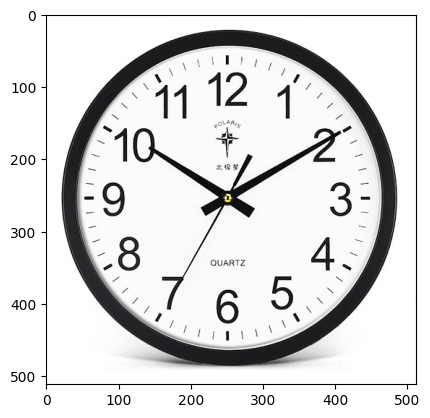

86.90116011001756
uint8
(512, 512, 3)


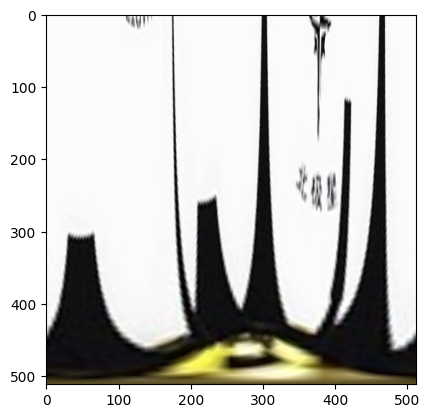

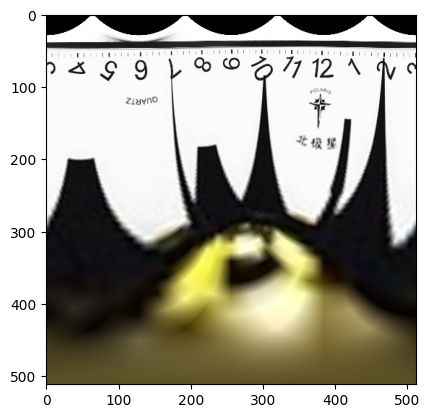

In [100]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt
import math
image = cv2.imread('/home/aistudio/work/clock.jpg')
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
height,width,channels = image.shape
print(image.shape)
plt.imshow(image)
plt.show()


rmax = math.hypot(width/2.0,height/2.0)
rmax_log = np.log(rmax)
mag_param = width/rmax_log
print(m)
centerx = width/2.0
centery = height/2.0

image_linear_polar = cv2.linearPolar(image,(centerx,centery),mag_param,
                cv2.WARP_FILL_OUTLIERS + cv2.INTER_LINEAR)

image_log_polar = cv2.logPolar(image,(centerx,centery),mag_param,
                cv2.WARP_FILL_OUTLIERS + cv2.INTER_LINEAR)

print(image_linear_polar.dtype)
image_linear_polar = np.transpose(image_linear_polar,(1,0,2))
image_linear_polar = np.flip(image_linear_polar,0)

image_log_polar = np.transpose(image_log_polar,(1,0,2))
image_log_polar = np.flip(image_log_polar,0)
print(image_linear_polar.shape)

plt.imshow(image_linear_polar)
plt.show()

plt.imshow(image_log_polar)
plt.show()

# 2025-9-25 home work 
## 1 using formard and backward mapping remake the code 
## 2 using slice to rescale the image to pyrimid 
## 3 require using one same image to test your code using answer sheet image  

# 2025-9-26 handmake homework
## 1 paint a bgr cmos using a A4 paper 
## 2 make a pinhole camera and take a few shots of images 

# 2025-9-26 homework paper sheet
## 1 paper form 2   rgb->gray ,cmyk, yiq,ycbcr, hsi,hsv   tranform formula and matrix form if exits
## 2 aistudio work  4.1-4.5